# N2 — ECG Signal Preprocessing Pipeline

**Purpose:** Develop, validate, and visually verify the shared preprocessing pipeline
(`Modules/preprocessing.py`) on real VitalDB waveforms before dataset construction.

**What this notebook covers:**
1. Load a raw ECG waveform from VitalDB (500 Hz)
2. Apply each preprocessing step individually with before/after plots
3. Validate `preprocess_ecg_window()` end-to-end
4. Test edge cases (flat signal, all-NaN window)

**Linked module:** `Modules/preprocessing.py`

In [1]:
# ---- Imports ----
import sys
from pathlib import Path

# Add Modules/ to path so we can import project modules
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'Modules'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vitaldb
from scipy.signal import butter, filtfilt, resample_poly

import config
from preprocessing import preprocess_ecg_window, is_valid_window

print('Python path OK')
print(f'WINDOW_SAMPLES = {config.WINDOW_SAMPLES}, TARGET_FS = {config.TARGET_FS} Hz')

Python path OK
WINDOW_SAMPLES = 2500, TARGET_FS = 250 Hz


In [2]:
# ---- Load a sample case from VitalDB ----
# Case 337 has Normal Sinus Rhythm + AFib segments — good for visual verification
SAMPLE_CASE_ID = 337

print(f'Downloading case {SAMPLE_CASE_ID} from VitalDB...')

# load_case returns shape (N, 1) at 500 Hz
raw_vals = vitaldb.load_case(SAMPLE_CASE_ID, ['SNUADC/ECG_II'], 1 / config.SOURCE_FS)
print(f'Raw array shape: {raw_vals.shape}')   # should be (N, 1)

# Extract single channel (column 0, NOT column 1 — only 1 column exists)
ecg_full = raw_vals[:, 0].astype(np.float64)
print(f'ECG samples (500 Hz): {len(ecg_full):,}')
print(f'Duration: {len(ecg_full) / config.SOURCE_FS:.1f} seconds')
print(f'NaN count: {np.isnan(ecg_full).sum()}')

Raw array shape: (4216298, 1)
ECG samples (500 Hz): 4,216,298
Duration: 8432.6 seconds
NaN count: 202


In [3]:
# ---- Load annotation for this case ----
ann_path = config.ANNOTATION_DIR / f'Annotation_file_{SAMPLE_CASE_ID}.csv'
annotations = pd.read_csv(ann_path)
print(annotations.head(10))
print(f'\nTotal beats: {len(annotations)}')
print(f'Rhythm classes: {annotations["rhythm_label"].unique()}')
print(f'\nAnalysis time range from metadata:')
meta = pd.read_csv(config.METADATA_CSV)
case_meta = meta[meta['case_id'] == SAMPLE_CASE_ID].iloc[0]
t_start = case_meta['analysis_start_time_sec']
t_end   = case_meta['analysis_end_time_sec']
print(f'  Start: {t_start:.1f}s, End: {t_end:.1f}s, Duration: {t_end - t_start:.1f}s')

   time_second beat_type rhythm_label  bad_signal_quality  \
0  7123.827778         N            N               False   
1  7125.086111         N            N               False   
2  7126.336111         N            N               False   
3  7127.588889         N            N               False   
4  7128.838889         N            N               False   
5  7130.075000         N            N               False   
6  7131.308333         N            N               False   
7  7132.536111         N            N               False   
8  7133.769444         N            N               False   
9  7134.983333         U            N               False   

  bad_signal_quality_label  
0                      NaN  
1                      NaN  
2                      NaN  
3                      NaN  
4                      NaN  
5                      NaN  
6                      NaN  
7                      NaN  
8                      NaN  
9                      NaN  

Total be

Analysis segment: 352,485 samples at 500 Hz = 705.0s


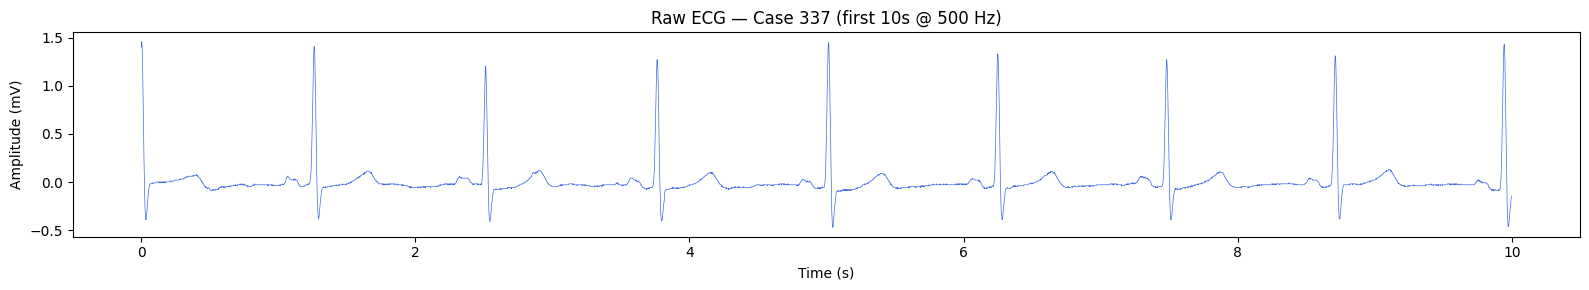

In [4]:
# ---- Slice to the annotated analysis segment ----
start_sample = int(t_start * config.SOURCE_FS)
end_sample   = int(t_end   * config.SOURCE_FS)
ecg_analysis = ecg_full[start_sample:end_sample]
print(f'Analysis segment: {len(ecg_analysis):,} samples at 500 Hz = {len(ecg_analysis)/config.SOURCE_FS:.1f}s')

# Plot the full analysis segment
t_axis = np.arange(len(ecg_analysis)) / config.SOURCE_FS
fig, ax = plt.subplots(figsize=(16, 3))
ax.plot(t_axis[:5000], ecg_analysis[:5000], lw=0.5, color='royalblue')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude (mV)')
ax.set_title(f'Raw ECG — Case {SAMPLE_CASE_ID} (first 10s @ 500 Hz)')
plt.tight_layout()
plt.show()

--- Step-by-step preprocessing ---
Step 1 (NaN fix): 0 NaN -> 0 NaN
Step 2 (Resample): 5000 -> 2500 samples
Step 3 (Bandpass 0.5-40.0 Hz): done
Step 4 (Z-score): mean=-0.0000, std=1.0000


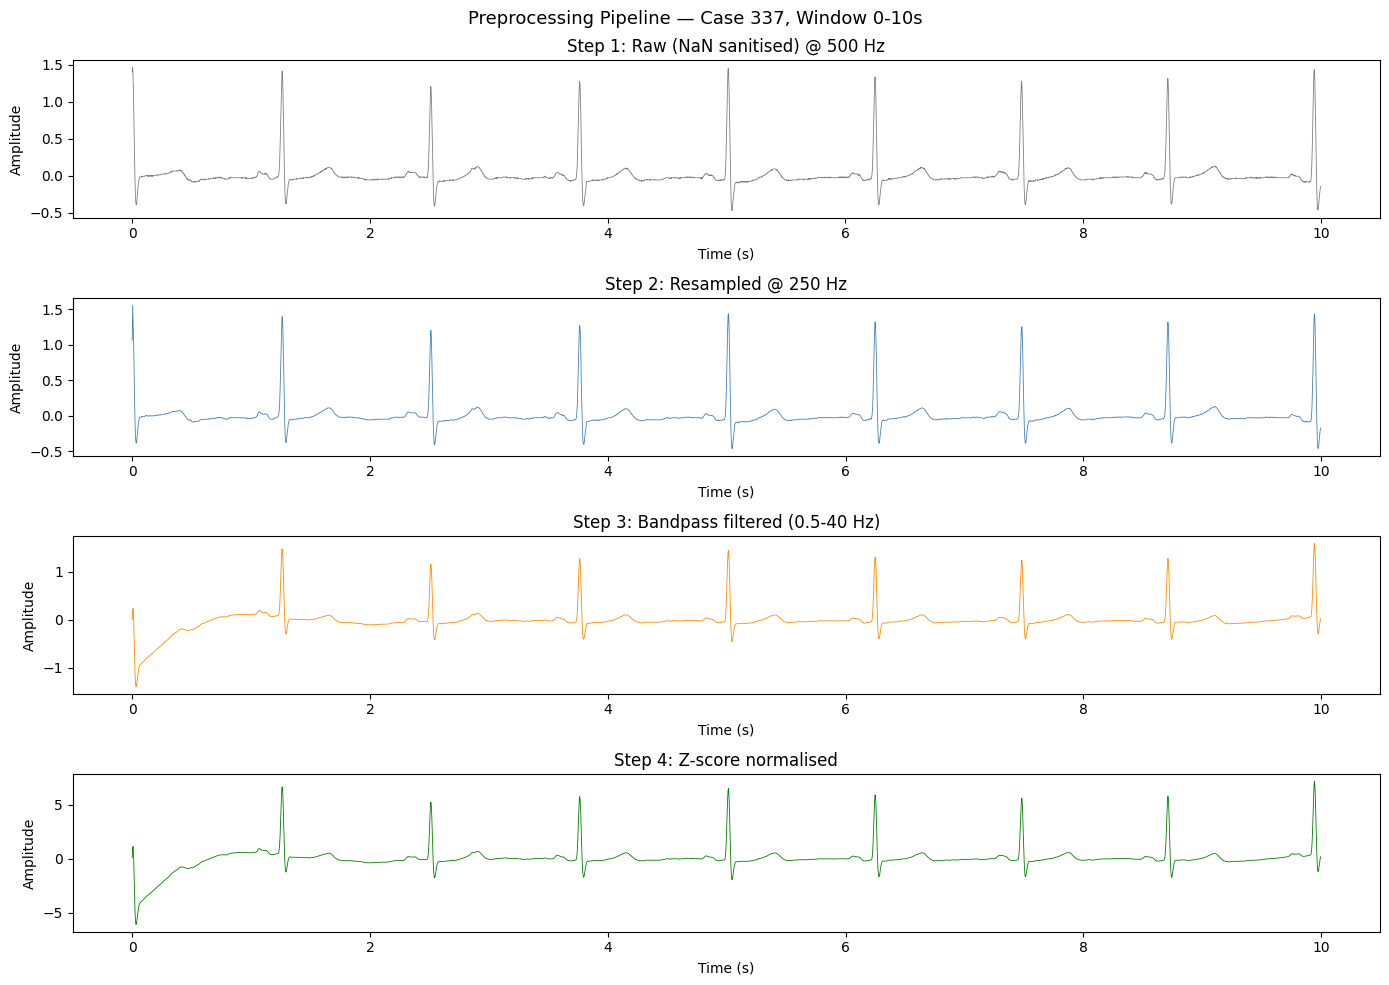

In [5]:
# ---- Step-by-step preprocessing on a 10-second window ----
# Extract the first 10s window (5000 samples at 500 Hz)
WIN_LEN_SOURCE = config.WINDOW_SAMPLES * (config.SOURCE_FS // config.TARGET_FS)  # 5000
raw_win = ecg_analysis[:WIN_LEN_SOURCE]

print('--- Step-by-step preprocessing ---')

# Step 1: Sanitise NaN/Inf
step1 = np.where(np.isfinite(raw_win), raw_win, 0.0)
print(f'Step 1 (NaN fix): {np.isnan(raw_win).sum()} NaN -> {np.isnan(step1).sum()} NaN')

# Step 2: Resample 500 Hz -> 250 Hz
step2 = resample_poly(step1, up=config.RESAMPLE_UP, down=config.RESAMPLE_DOWN)
print(f'Step 2 (Resample): {len(step1)} -> {len(step2)} samples')

# Step 3: Butterworth bandpass filter
nyq = config.TARGET_FS / 2
b, a = butter(config.FILTER_ORDER, 
              [config.FILTER_LOWCUT/nyq, config.FILTER_HIGHCUT/nyq], 
              btype='band')
step3 = filtfilt(b, a, step2)
print(f'Step 3 (Bandpass {config.FILTER_LOWCUT}-{config.FILTER_HIGHCUT} Hz): done')

# Step 4: Z-score normalisation
step4 = (step3 - step3.mean()) / (step3.std() + 1e-6)
print(f'Step 4 (Z-score): mean={step4.mean():.4f}, std={step4.std():.4f}')

# Plot all steps side-by-side
t_250 = np.arange(config.WINDOW_SAMPLES) / config.TARGET_FS
t_500 = np.arange(WIN_LEN_SOURCE) / config.SOURCE_FS

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=False)
axes[0].plot(t_500, step1, lw=0.6, color='gray');        axes[0].set_title('Step 1: Raw (NaN sanitised) @ 500 Hz')
axes[1].plot(t_250, step2, lw=0.6, color='steelblue');   axes[1].set_title('Step 2: Resampled @ 250 Hz')
axes[2].plot(t_250, step3, lw=0.6, color='darkorange');  axes[2].set_title('Step 3: Bandpass filtered (0.5-40 Hz)')
axes[3].plot(t_250, step4, lw=0.6, color='green');       axes[3].set_title('Step 4: Z-score normalised')
for ax in axes:
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Amplitude')
plt.suptitle(f'Preprocessing Pipeline — Case {SAMPLE_CASE_ID}, Window 0-10s', fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
# ---- Test preprocess_ecg_window() end-to-end ----
processed = preprocess_ecg_window(raw_win)
print(f'Output shape : {processed.shape}')   # should be (2500,)
print(f'Output dtype : {processed.dtype}')   # should be float32
print(f'Output mean  : {processed.mean():.4f}')  # ~0
print(f'Output std   : {processed.std():.4f}')   # ~1
assert processed.shape == (config.WINDOW_SAMPLES,), 'Shape mismatch!'
print('PASS: preprocess_ecg_window() output shape correct')

Output shape : (2500,)
Output dtype : float32
Output mean  : 0.0000
Output std   : 1.0000
PASS: preprocess_ecg_window() output shape correct


In [7]:
# ---- Edge case tests ----

# Test 1: is_valid_window — mostly NaN
nan_win = np.full(WIN_LEN_SOURCE, np.nan)
print(f'All-NaN window valid? {is_valid_window(nan_win)}')  # should be False

# Test 2: is_valid_window — mostly valid
partial_win = raw_win.copy()
print(f'Real window valid?    {is_valid_window(partial_win)}')  # should be True

# Test 3: Flat/constant signal (std=0) should not divide by zero
flat_win = np.zeros(WIN_LEN_SOURCE)
flat_processed = preprocess_ecg_window(flat_win)
print(f'Flat signal output std: {flat_processed.std():.6f}')  # ~0 but no exception
print('PASS: Flat signal does not raise ZeroDivisionError')

# Test 4: Window with 40% NaN (above threshold, should still preprocess with NaN->0)
partial_nan_win = raw_win.copy()
partial_nan_win[:int(0.4 * WIN_LEN_SOURCE)] = np.nan
partial_nan_processed = preprocess_ecg_window(partial_nan_win)
print(f'40%-NaN window output shape: {partial_nan_processed.shape}')  # (2500,)

print('\nAll edge case tests passed.')

All-NaN window valid? False
Real window valid?    True
Flat signal output std: 0.000000
PASS: Flat signal does not raise ZeroDivisionError
40%-NaN window output shape: (2500,)

All edge case tests passed.


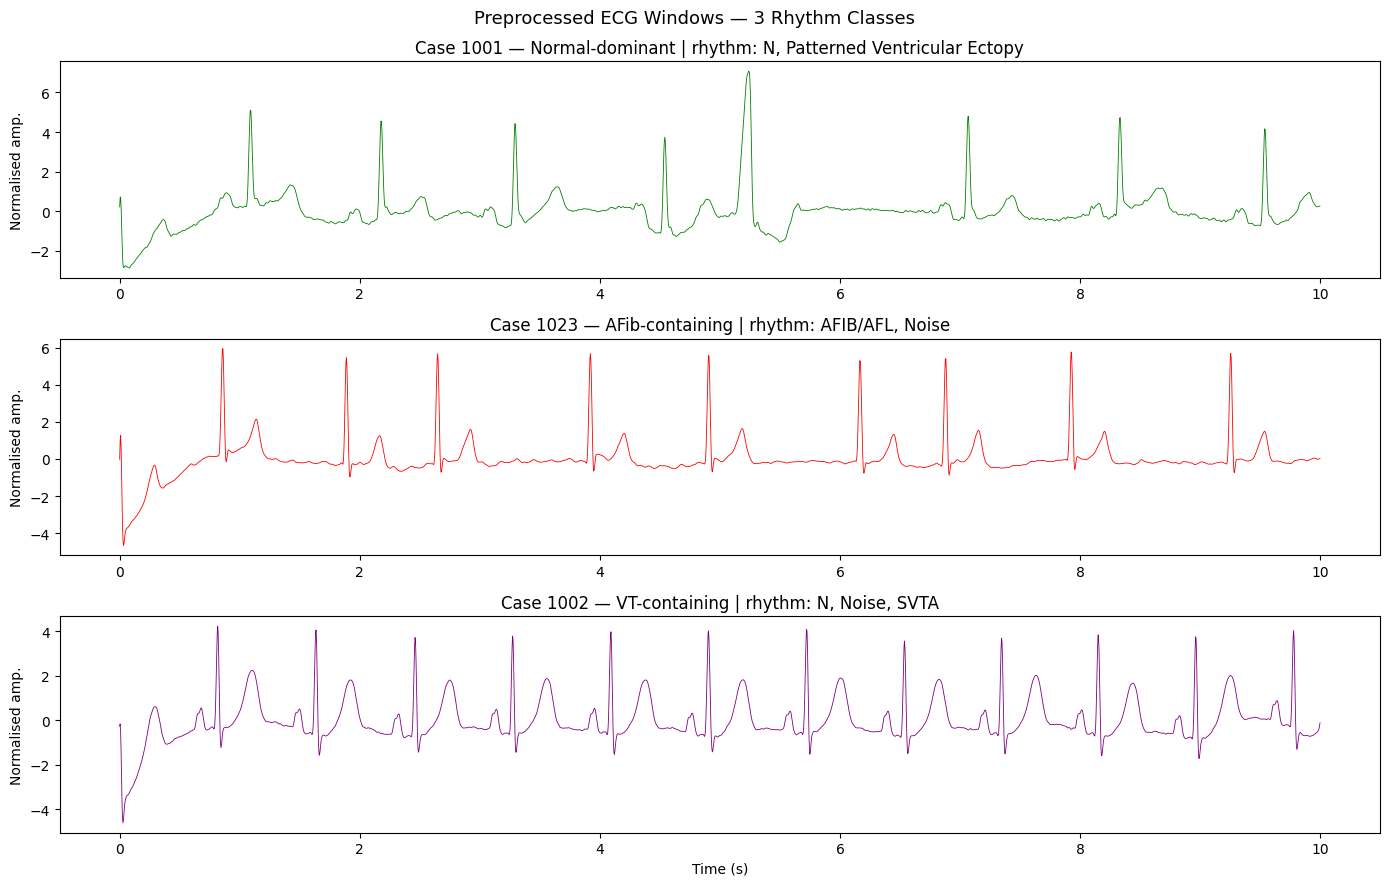

Comparison complete.


In [8]:
# ---- Compare preprocessing on 3 different rhythm classes ----
# Pick cases with known different rhythms from metadata
meta = pd.read_csv(config.METADATA_CSV)

# Find 3 cases: one Normal-only, one AFib-containing, one VT-containing
normal_only = meta[~meta['rhythm_classes'].str.contains('AFIB|VT|SVTA', na=False)].iloc[0]
afib_case   = meta[meta['rhythm_classes'].str.contains('AFIB', na=False)].iloc[0]
vt_case     = meta[meta['rhythm_classes'].str.contains('VT', na=False)].iloc[0]

sample_cases = [
    (int(normal_only['case_id']), 'Normal-dominant',   'green'),
    (int(afib_case['case_id']),   'AFib-containing',   'red'),
    (int(vt_case['case_id']),     'VT-containing',     'purple'),
]

fig, axes = plt.subplots(3, 1, figsize=(14, 9))

for (cid, label, color), ax in zip(sample_cases, axes):
    try:
        vals = vitaldb.load_case(cid, ['SNUADC/ECG_II'], 1 / config.SOURCE_FS)
        cid_meta = meta[meta['case_id'] == cid].iloc[0]
        s_start  = int(cid_meta['analysis_start_time_sec'] * config.SOURCE_FS)
        raw_w    = vals[s_start: s_start + WIN_LEN_SOURCE, 0]
        proc_w   = preprocess_ecg_window(raw_w)
        t        = np.arange(config.WINDOW_SAMPLES) / config.TARGET_FS
        ax.plot(t, proc_w, lw=0.6, color=color)
        ax.set_title(f'Case {cid} — {label} | rhythm: {cid_meta["rhythm_classes"]}')
        ax.set_ylabel('Normalised amp.')
    except Exception as e:
        ax.set_title(f'Case {cid} — {label} [FAILED: {e}]')

axes[-1].set_xlabel('Time (s)')
plt.suptitle('Preprocessed ECG Windows — 3 Rhythm Classes', fontsize=13)
plt.tight_layout()
plt.show()
print('Comparison complete.')